<div style="display: flex; background-color: RGB(255,114,0);" >
<h1 style="margin: auto; padding: 30px; ">ANALYSE DU STOCK ET DES VENTES DU SITE BOTTLENECK</h1>
</div>

# OBJECTIF DE CE NOTEBOOK

Bienvenue dans l'outil plébiscité par les analystes de données Jupyter.

Il s'agit d'un outil permettant de mixer et d'alterner code, texte et graphiques.

Cet outil est formidable pour plusieurs raisons:

+ Il permet de tester des lignes de codes au fur et à mesure de votre rédaction, de constater immédiatement le résultat d'une instruction, de la corriger si nécessaire.
+ Il permet aussi de rédiger du texte pour expliquer l'approche suivie ou les résultats d'une analyse et de le mettre en forme grâce à du code html ou plus simple avec **Markdown**
+ Il est possible d'ajouter des graphiques

Pour vous aider dans vos premiers pas à l'usage de Jupyter et de Python, nous avons rédigé ce notebook en vous indiquant les instructions à suivre.

Il vous suffit pour cela de saisir le code Python répondant à l'instruction donnée.

Vous verrez de temps à autre le code Python répondant à une instruction donnée mais cela est fait pour vous aider à comprendre la nature du travail qui vous est demandé.

Et gardez à l'esprit qu'il n'y a pas de solution unique pour résoudre un problème et qu'il y a autant de résolutions de problèmes que de développeurs ;)...



<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 1 - Importation des librairies et chargement des fichiers</h2>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">1.1 - Importation des librairies</h3>
</div>

In [1]:
#Importation de la librairie Pandas
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno

#Configuration de l'affichage des DataFrames Pandas
pd.set_option('display.max_colwidth', None)
pd.set_option('display.max_columns', None)

In [2]:
#Importation de la librairie plotly express
import plotly.express as px

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">1.2 - Chargements des fichiers</h3>
</div>

In [3]:
#Importation du fichier web.xlsx
df_web = pd.read_csv(r"web.csv")
#Importation du fichier erp.xlsx
df_erp = pd.read_csv(r"erp.csv")
#Importation du fichier liaison.xlsx
df_liason = pd.read_csv(r"liaison.csv")

In [4]:
df_liason.head()

,id_web,product_id
0,15298,3847
1,15296,3849
2,15300,3850
3,19814,4032
4,19815,4039


<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 2 - Analyse exploratoire des fichiers</h2>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.1 - Analyse exploratoire du fichier erp.xlsx</h3>
</div>

In [5]:
#Afficher les dimensions du dataset
print("Le tableau comporte {} observation(s) ou article(s)".format(df_erp.shape[0]))
print("Le tableau comporte {} colonne(s)".format(df_erp.shape[1]))
print('Le tableau comporte {} valeur(s) manquante(s)'.format(df_erp.isnull().sum().sum()))
print("Le tableau comporte {} doublon(s)".format(df_erp.duplicated().sum()))
print("Le tableau comporte {} types de données différents".format(df_erp.dtypes))

Le tableau comporte 825 observation(s) ou article(s)
Le tableau comporte 6 colonne(s)
Le tableau comporte 0 valeur(s) manquante(s)
Le tableau comporte 0 doublon(s)
Le tableau comporte product_id         int64
onsale_web         int64
price             object
stock_quantity     int64
stock_status      object
purchase_price    object
dtype: object types de données différents


In [6]:
#Consulter le nombre de colonnes
#La nature des données dans chacune des colonnes
df_erp.info()



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 825 entries, 0 to 824
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   product_id      825 non-null    int64 
 1   onsale_web      825 non-null    int64 
 2   price           825 non-null    object
 3   stock_quantity  825 non-null    int64 
 4   stock_status    825 non-null    object
 5   purchase_price  825 non-null    object
dtypes: int64(3), object(3)
memory usage: 38.8+ KB


In [7]:
#Afficher les 5 premières lignes de la table
df_erp.head()

,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price
0,3847,1,"24,2",16,instock,"12,88"
1,3849,1,"34,3",10,instock,"17,54"
2,3850,1,"20,8",0,outofstock,"10,64"
3,4032,1,"14,1",26,instock,"6,92"
4,4039,1,46,3,outofstock,"23,77"


In [8]:
#Vérifier si il y a des lignes en doublon dans la colonne product_id
df_erp["product_id"].duplicated().sum()
print("Il y a", df_erp.duplicated().sum(), "lignes en doubles")
print(" ")

#on peut dire que Product ID est clé unique

Il y a 0 lignes en doubles
 


In [9]:
#cambio object to float for price & purchase_price, but first replace , to . 
# pour les décimales et pouvoir utiliser les fonctions mathématiques et changer en float
cols_numeric_changes = ["price", "purchase_price"]

for col in cols_numeric_changes:
    df_erp[col] = df_erp[col].str.replace(",",".").astype(float)

df_erp.head().info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   product_id      5 non-null      int64  
 1   onsale_web      5 non-null      int64  
 2   price           5 non-null      float64
 3   stock_quantity  5 non-null      int64  
 4   stock_status    5 non-null      object 
 5   purchase_price  5 non-null      float64
dtypes: float64(2), int64(3), object(1)
memory usage: 372.0+ bytes


In [10]:
#vérifier stock négatifs in stock_quantity
print(df_erp["stock_quantity"].isnull().sum())
print(df_erp.loc[df_erp['stock_quantity'] < 0])


0
     product_id  onsale_web  price  stock_quantity stock_status  \
449        4973           0   10.0             -10   outofstock   
573        5700           1   44.5              -1   outofstock   

     purchase_price  
449            4.96  
573           22.30  


In [11]:
#val_null in price & purchase_price
print(df_erp["price"].isnull().sum())
print(df_erp["purchase_price"].isnull().sum())


0
0


In [12]:
#cols  control et change. verifier qu il n y a pas des valeur negatif
cols_control = ['onsale_web', 'price', 'stock_quantity', 'purchase_price']

for col in cols_control:
    n_negs = (df_erp[col]<0).sum() or (df_erp[col].isnull()).sum()
    if n_negs > 0:
        print(f'attenzione la colonna {col} ha {n_negs} numeri negativi')
        print(df_erp.loc[df_erp[col] < 0])
    else:
        print(f'la colonna {col} non contiene numeri negativi')

la colonna onsale_web non contiene numeri negativi
attenzione la colonna price ha 3 numeri negativi
     product_id  onsale_web  price  stock_quantity stock_status  \
151        4233           0  -20.0               0   outofstock   
469        5017           0   -8.0               0   outofstock   
739        6594           0   -9.1              19      instock   

     purchase_price  
151           10.33  
469            4.34  
739            4.61  
attenzione la colonna stock_quantity ha 2 numeri negativi
     product_id  onsale_web  price  stock_quantity stock_status  \
449        4973           0   10.0             -10   outofstock   
573        5700           1   44.5              -1   outofstock   

     purchase_price  
449            4.96  
573           22.30  
la colonna purchase_price non contiene numeri negativi


In [13]:
#changer chiffres négatifs en 0 pour stock_quantity et enlever les - pour price
#stock quantity
df_erp['stock_quantity'] = df_erp['stock_quantity'].clip(lower=0)

#price
df_erp['price'] = df_erp['price'].abs()
df_erp.head()

,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price
0,3847,1,24.2,16,instock,12.88
1,3849,1,34.3,10,instock,17.54
2,3850,1,20.8,0,outofstock,10.64
3,4032,1,14.1,26,instock,6.92
4,4039,1,46.0,3,outofstock,23.77


In [14]:
#Afficher les valeurs distinctes de la colonne stock_status
df_erp['stock_status'].unique()

array(['instock', 'outofstock'], dtype=object)

In [15]:
#À quelle(s) autre(s) colonne(s) sont-elles liées ?
anomalie = df_erp.loc[(df_erp['stock_status'] == 'outofstock') & (df_erp['stock_quantity'] > 0)]
if not anomalie.empty:
    print("J'ai trouvé des produits qui sont déclarés 'outofstock' mais ont une quantité de stock positive:")
    print(anomalie)
else:
    print("Aucune anomalie trouvée!")

anomalie2 = df_erp.loc[(df_erp['stock_status'] == 'instock') & (df_erp['stock_quantity'] == 0)]
if not anomalie2.empty:
    print("J'ai trouvé des produits qui sont déclarés 'instock' mais n'ont aucune quantité de stock:")
    print(anomalie2)
else:
    print("Aucune anomalie trouvée!")

J'ai trouvé des produits qui sont déclarés 'outofstock' mais ont une quantité de stock positive:
   product_id  onsale_web  price  stock_quantity stock_status  purchase_price
4        4039           1   46.0               3   outofstock           23.77
J'ai trouvé des produits qui sont déclarés 'instock' mais n'ont aucune quantité de stock:
     product_id  onsale_web  price  stock_quantity stock_status  \
398        4885           1   18.7               0      instock   

     purchase_price  
398            9.66  


In [16]:
#correction stock_quantity négatifs ou erreur in stock_status - pour verifier recharger le bloc de code précédent
df_erp.loc[(df_erp['stock_status'] == 'outofstock') & (df_erp['stock_quantity']>0), 'stock_status'] = 'instock'
df_erp.loc[(df_erp['stock_status'] == 'instock') & (df_erp['stock_quantity']==0), 'stock_status'] = 'outofstock'

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.1.1 - Analyse exploratoire de chaque variable du fichier erp.xlsx</h3>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.1.1.1 - Analyse de la variable PRIX</h3>
</div>

In [17]:
###############
## LES PRIX  ##
###############

#Afficher le prix minimum de la colonne "price"
print(f'Le prix minium de la colonne price est de : €{df_erp['price'].min()}')
#Afficher le prix maximum de la colonne "price"
print(f'Le prix maximum de la colonne price est de : €{df_erp['price'].max()}')
#Afficher les prix inférieurs à 0 (qu'est-ce qu'il faut en faire ?)


Le prix minium de la colonne price est de : €5.2
Le prix maximum de la colonne price est de : €225.0


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.1.1.2 - Analyse de la variable STOCK</h3>
</div>

In [18]:
#######################
### stock_quantity  ###
#######################

#Vérification de la colonne stock quantity
#Afficher la quantité minimum de la colonne "stock_quantity"
print(f'La quantité mininum dans la colonne Stock_quantity est de : {df_erp["stock_quantity"].min()}')
#Afficher la quantité maximum de la colonne "stock_quantity
print(f'La quantité maximum dans la colonne Stock_quantity est de : {df_erp["stock_quantity"].max()}')

#Afficher les stocks inférieurs à 0 (qu'est-ce qu'il faut en faire ?) - deja resolu plus en haut


La quantité mininum dans la colonne Stock_quantity est de : 0
La quantité maximum dans la colonne Stock_quantity est de : 145


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.1.1.3 - Analyse de la variable ONSALE_WEB</h3>
</div>

In [19]:
#Vérification de la colonne onsale_web et des valeurs qu'elle contient. Que signifient-elles?
#elle doit etre 0 ou 1 si c'est 1 le produit est en vente sur le web sinon non
df_erp.head(30)

,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price
0,3847,1,24.2,16,instock,12.88
1,3849,1,34.3,10,instock,17.54
2,3850,1,20.8,0,outofstock,10.64
3,4032,1,14.1,26,instock,6.92
4,4039,1,46.0,3,instock,23.77
5,4040,1,34.3,12,instock,18.25
6,4041,1,32.7,12,instock,17.57
7,4042,1,31.2,15,instock,15.48
8,4043,1,60.0,0,outofstock,29.45
9,4045,1,42.6,5,instock,22.01


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.1.1.4 - Analyse de la variable prix d'achat</h3>
</div>

In [20]:
######################
##   prix d'achat   ##
######################

#Vérification de la colonne purchase_price : 
#Afficher le ou les prix non renseignés dans la colonne "purchase_price"
print(df_erp[df_erp['purchase_price'].isnull()])
#Afficher le prix minimum de la colonne "purchase_price"
print(f'Le prix minimum est de {df_erp["purchase_price"].min()}')
#Afficher le prix maximum de la colonne "purchase_price"
print(f'Le prix maximum est de {df_erp["purchase_price"].max()}')

Empty DataFrame
Columns: [product_id, onsale_web, price, stock_quantity, stock_status, purchase_price]
Index: []
Le prix minimum est de 2.74
Le prix maximum est de 137.81


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.2 - Analyse exploratoire du fichier web.xlsx</h3>
</div>
 

In [21]:
#Dimension du dataset
df_web.info()
#Nombre d'observations

#Nombre de caractéristiques
print("Le tableau comporte {} observation(s) ou article(s)".format(df_web.shape[0]))
print("Le tableau comporte {} colonne(s)".format(df_web.shape[1]))
print('Le tableau comporte {} valeur(s) manquante(s)'.format(df_web.isnull().sum().sum()))
print("Le tableau comporte {} doublon(s)".format(df_web.duplicated().sum()))
print("Le tableau comporte {} types de données différents".format(df_web.dtypes))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1513 entries, 0 to 1512
Data columns (total 29 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   sku                    1428 non-null   object 
 1   virtual                1513 non-null   int64  
 2   downloadable           1513 non-null   int64  
 3   rating_count           1513 non-null   int64  
 4   average_rating         1430 non-null   float64
 5   total_sales            1430 non-null   float64
 6   tax_status             716 non-null    object 
 7   tax_class              0 non-null      float64
 8   post_author            1430 non-null   float64
 9   post_date              1430 non-null   object 
 10  post_date_gmt          1430 non-null   object 
 11  post_content           0 non-null      float64
 12  product_type           1429 non-null   object 
 13  post_title             1430 non-null   object 
 14  post_excerpt           716 non-null    object 
 15  post

In [22]:
#garder les colonnes utiles pour la suite de l'analyse
df_web = df_web[["sku", "total_sales", "product_type", "post_title", "post_name"]]


In [23]:
print(f'dans la colonne sku il y a {df_web["sku"].isnull().sum()} valeurs nulls')
print(f'dans la colonne total_sales il y a {df_web["total_sales"].isnull().sum()} valeurs nulls')
print(f'dans la colonne product_type il y a {df_web["product_type"].isnull().sum()} valeurs nulls')
print(f'dans la colonne post_title il y a {df_web["post_title"].isnull().sum()} valeurs nulls')
print(f'dans la colonne post_name il y a {df_web["post_name"].isnull().sum()} valeurs nulls')


dans la colonne sku il y a 85 valeurs nulls
dans la colonne total_sales il y a 83 valeurs nulls
dans la colonne product_type il y a 84 valeurs nulls
dans la colonne post_title il y a 83 valeurs nulls
dans la colonne post_name il y a 83 valeurs nulls


In [24]:
#verification doublons
numero_doublons = df_web.duplicated().sum()
print(numero_doublons)

791


In [25]:
#doublons NaN 
df_doublons = df_web[df_web.duplicated(keep=False)]
df_doublons.head()

,sku,total_sales,product_type,post_title,post_name
0,11862,3.0,Vin,Gilles Robin Hermitage Rouge 2012,gilles-robin-hermitage-2012
1,16057,5.0,Vin,Domaine Pellé Sancerre Rouge La Croix Au Garde 2017,pelle-sancerre-rouge-la-croix-au-garde-2017
2,14692,5.0,Vin,Château Fonréaud Bordeaux Blanc Le Cygne 2016,fonreaud-bordeaux-blanc-le-cygne-2016
3,16295,14.0,Vin,Moulin de Gassac IGP Pays d'Hérault Guilhem Rosé 2019,moulin-de-gassac-igp-pays-dherault-guilhem-rose-2019
4,15328,2.0,Vin,Agnès Levet Côte Rôtie Maestria 2017,agnes-levet-cote-rotie-maestria-2017


In [26]:
#drop des lignes NaN doublons
df_web = df_web.dropna(how = 'all')


In [27]:
#doublons dans 'sku'
df_web_sku_doublons = df_web[df_web.duplicated(subset=['sku'], keep=False)]
df_web_sku_doublons.sort_values(by='sku')


,sku,total_sales,product_type,post_title,post_name
668,10014,10.0,Gin,Darnley's London Dry Gin Original,darnleys-london-dry-gin-original
1030,10014,10.0,Gin,Darnley's London Dry Gin Original,darnleys-london-dry-gin-original
887,10459,4.0,Vin,Alphonse Mellot Sancerre Rouge Génération XIX 2011,alphonse-mellot-sancerre-rouge-generation-xix-2011
748,10459,4.0,Vin,Alphonse Mellot Sancerre Rouge Génération XIX 2011,alphonse-mellot-sancerre-rouge-generation-xix-2011
802,10775,6.0,Vin,Albert Mann Pinot Gris Vendanges Tardives Altenbourg 2011,albert-mann-pinot-gris-vendanges-tardives-altenbourg-2011
...,...,...,...,...,...
728,9937,2.0,Vin,Marcel Richaud Cairanne Rouge Les Estrambords 2011,marcel-richaud-cairanne-rouge-les-estrambords-2011
842,bon-cadeau-25-euros,7.0,Autre,Bon cadeau de 25€,bon-cadeau-de-25-euros
1387,bon-cadeau-25-euros,7.0,NaN,Bon cadeau de 25€,bon-cadeau-de-25-euros
1084,NaN,-56.0,Vin,Pierre Jean Villa Condrieu Jardin Suspendu 2018,pierre-jean-villa-condrieu-suspendu-2018


In [28]:
#ajout valeurs sku pour lignes 1084 (5075) et 1087 (5070) retrouvé sur le excel d'origine
df_web.loc[1084, 'sku'] = '5075'
df_web.loc[1087, 'sku'] = '5070'

In [29]:
#drop des doublons
df_web = df_web.drop_duplicates(subset=['sku'], keep='first')

In [30]:
#correction total_sales negatif
df_web['total_sales'] = df_web['total_sales'].abs()

display(df_web.loc[df_web['total_sales'] < 0])

,sku,total_sales,product_type,post_title,post_name


In [31]:
df_web.info()

<class 'pandas.core.frame.DataFrame'>
Index: 716 entries, 0 to 1391
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sku           716 non-null    object 
 1   total_sales   716 non-null    float64
 2   product_type  716 non-null    object 
 3   post_title    716 non-null    object 
 4   post_name     716 non-null    object 
dtypes: float64(1), object(4)
memory usage: 33.6+ KB


In [32]:
#Si vous avez défini des colonnes à supprimer, effectuer l'opération
df_web.head()

,sku,total_sales,product_type,post_title,post_name
0,11862,3.0,Vin,Gilles Robin Hermitage Rouge 2012,gilles-robin-hermitage-2012
1,16057,5.0,Vin,Domaine Pellé Sancerre Rouge La Croix Au Garde 2017,pelle-sancerre-rouge-la-croix-au-garde-2017
2,14692,5.0,Vin,Château Fonréaud Bordeaux Blanc Le Cygne 2016,fonreaud-bordeaux-blanc-le-cygne-2016
3,16295,14.0,Vin,Moulin de Gassac IGP Pays d'Hérault Guilhem Rosé 2019,moulin-de-gassac-igp-pays-dherault-guilhem-rose-2019
4,15328,2.0,Vin,Agnès Levet Côte Rôtie Maestria 2017,agnes-levet-cote-rotie-maestria-2017


In [33]:
#changer le type de données de la colonne sku en int, mais certains ont des traits d'union et ne peuvent pas être convertis en int, alors on laisse en object

In [34]:
#Visualisation des valeurs de la colonne sku
df_web['sku'].unique()


array(['11862', '16057', '14692', '16295', '15328', '15471', '16515',
       '16246', '13572', '16513', '16585', '16269', '15526', '12869',
       '15575', '11586', '14338', '15425', '16560', '15361', '13809',
       '11587', '15022', '14323', '16342', '16029', '15475', '13754',
       '14680', '15875', '9636', '13849', '13662', '16564', '13557',
       '15429', '14712', '15032', '15481', '15448', '16580', '15441',
       '804', '15300', '13958', '16071', '15678', '13895', '15711',
       '12882', '16053', '13766', '16247', '12640', '15292', '15476',
       '15670', '16189', '16038', '14864', '16044', '15324', '15531',
       '15953', '15413', '15733', '14366', '15895', '15892', '16472',
       '15185', '16010', '15793', '15849', '12315', '15741', '15934',
       '15148', '15781', '15659', '15106', '15490', '14507', '14149',
       '16307', '13736', '14090', '16037', '15758', '14661', '12587',
       '15337', '15489', '15201', '16305', '16131', '13435', '15747',
       '12203', '14509'

In [35]:
print(df_web.loc[df_web['sku'] == '523'])

     sku  total_sales product_type                    post_title  \
899  523          0.0       Cognac  Cognac Normandin Mercier VFC   

                        post_name  
899  cognac-normandin-mercier-vfc  


In [36]:
#Si vous avez identifié des codes articles ne respectant pas la régle de codification, consultez-les '13127-1' et 'bon-cadeau-25-euros'.
print(df_web.loc[df_web['sku'] == '13127-1'])
print(df_web.loc[df_web['sku'] == 'bon-cadeau-25-euros'])

         sku  total_sales product_type  \
272  13127-1          4.0          Vin   

                                       post_title  \
272  Clos du Mont-Olivet Châteauneuf-du-Pape 2007   

                                          post_name  
272  clos-du-mont-olivet-chateauneuf-du-pape-2007-2  
                     sku  total_sales product_type         post_title  \
842  bon-cadeau-25-euros          7.0        Autre  Bon cadeau de 25€   

                  post_name  
842  bon-cadeau-de-25-euros  


In [37]:
#Identifier les lignes sans code article
#y en avait 2 de produits sans code article, mais on les a corrigé en se référant au fichier excel d'origine 5075 et 5070

In [38]:
#Pour les codes articles identifiés, réaliser une analyse et définir l'action à entreprendre - deja fait

In [39]:
#La clé pour chaque ligne est-elle unique? autrement dit, y a-t-il des doublons?
print('dans le fichier web nous avons un nombre de doublons :', df_web['sku'].duplicated().sum())


dans le fichier web nous avons un nombre de doublons : 0


In [40]:
#Les lignes sans code article semblent être toutes non renseignées
#Pour s'en assurer, réaliser les étapes suivantes:
#1 - Créer un dataframe avec uniquement les lignes sans code article
df_web_sku_null = df_web[df_web['sku'].isnull()]
#2 - Utiliser la fonction df.info() sur ce nouveau dataframe pour observer le nombre de valeurs renseignées dans chacune des colonnes
df_web_sku_null.info()
#3 - Que constatez-vous? sku c est product_id

<class 'pandas.core.frame.DataFrame'>
Index: 0 entries
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sku           0 non-null      object 
 1   total_sales   0 non-null      float64
 2   product_type  0 non-null      object 
 3   post_title    0 non-null      object 
 4   post_name     0 non-null      object 
dtypes: float64(1), object(4)
memory usage: 0.0+ bytes


In [41]:
print(df_web[df_web['sku'] == 13771])

Empty DataFrame
Columns: [sku, total_sales, product_type, post_title, post_name]
Index: []


In [42]:
display(df_web)

,sku,total_sales,product_type,post_title,post_name
0,11862,3.0,Vin,Gilles Robin Hermitage Rouge 2012,gilles-robin-hermitage-2012
1,16057,5.0,Vin,Domaine Pellé Sancerre Rouge La Croix Au Garde 2017,pelle-sancerre-rouge-la-croix-au-garde-2017
2,14692,5.0,Vin,Château Fonréaud Bordeaux Blanc Le Cygne 2016,fonreaud-bordeaux-blanc-le-cygne-2016
3,16295,14.0,Vin,Moulin de Gassac IGP Pays d'Hérault Guilhem Rosé 2019,moulin-de-gassac-igp-pays-dherault-guilhem-rose-2019
4,15328,2.0,Vin,Agnès Levet Côte Rôtie Maestria 2017,agnes-levet-cote-rotie-maestria-2017
...,...,...,...,...,...
1325,16043,10.0,Vin,Pierre Gaillard Saint-Joseph Rouge 2018,pierre-gaillard-saint-joseph-2018
1327,15845,9.0,Vin,Château Jean Faure Saint-Emilion Grand Cru 2016,chateau-jean-faure-saint-emilion-grand-cru-2016
1339,15951,9.0,Vin,Jacqueson Rully Rouge 1er Cru Les Preaux 2018,jacqueson-rully-rouge-1er-cru-les-preaux-2018
1353,13074,4.0,Vin,Château de Vaudieu Châteauneuf-du-Pape L'Avenue 2015,chateau-de-vaudieu-chateauneuf-du-pape-lavenue-2015


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.3 - Analyse exploratoire du fichier liaison.xlsx</h3>
</div>

In [43]:
#Dimension du dataset
#Nombre d'observations
df_liason.info()
#Nombre de caractéristiques
print("Le tableau comporte {} observation(s) ou article(s)".format(df_liason.shape[0]))
print("Le tableau comporte {} colonne(s)".format(df_liason.shape[1]))
print('Le tableau comporte {} valeur(s) manquante(s)'.format(df_liason.isnull().sum().sum()))
print("Le tableau comporte {} doublon(s)".format(df_liason.duplicated().sum()))
print("Le tableau comporte {} types de données différents".format(df_liason.dtypes))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 825 entries, 0 to 824
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   id_web      734 non-null    object
 1   product_id  825 non-null    int64 
dtypes: int64(1), object(1)
memory usage: 13.0+ KB
Le tableau comporte 825 observation(s) ou article(s)
Le tableau comporte 2 colonne(s)
Le tableau comporte 91 valeur(s) manquante(s)
Le tableau comporte 0 doublon(s)
Le tableau comporte id_web        object
product_id     int64
dtype: object types de données différents


In [44]:
df_liason_null = df_liason[df_liason['id_web'].isnull()]
display(df_liason_null)

,id_web,product_id
19,NaN,4055
49,NaN,4090
50,NaN,4092
119,NaN,4195
131,NaN,4209
...,...,...
817,NaN,7196
818,NaN,7200
819,NaN,7201
820,NaN,7203


In [45]:
df_liason.isnull().sum() # Les 91 NaN c est des produits non vendus sur le web et donc pas de id_web

id_web        91
product_id     0
dtype: int64

In [46]:
#Consulter le nombre de colonnes
#La nature des données dans chacune des colonnes
#Le nombre de valeurs présentes dans chacune des colonnes


In [47]:
#Les valeurs de la colonne "product_id" sont-elles toutes uniques?
print(f'il y a {df_liason["product_id"].duplicated().sum()} doublons dans la colonne "product_id"')

il y a 0 doublons dans la colonne "product_id"


In [48]:
#Les valeurs de la colonne "id_web" sont-elles toutes uniques? 90doublons d un id_web, donc 91 elements non renseignés
print(f'il y a {df_liason["id_web"].duplicated().sum()} doublons dans la colonne "id_web"')

il y a 90 doublons dans la colonne "id_web"


In [49]:
#Avons-nous des articles sans correspondance? 91


<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 3 - Jonction des fichiers</h2>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 3.1 - Jonction du fichier df_erp et df_liaison</h3>
</div>

In [50]:
#Fusion des fichiers df_erp et df_liaison. how = 'left' garder tous a dx e ajouter les elements à gauche
# Aggiungiamo indicator=True = mette true o false o both
df_merged = pd.merge(df_erp, df_liason, on='product_id', how='left', indicator=True)

In [51]:
#Y a t-il des lignes ne "matchant" pas entre les 2 fichiers?
print(df_merged['_merge'].value_counts())
#825 match, tutto ok, 91 produits non vendus sur le web et donc pas de id_web, ces 91 produits sont présents dans le fichier erp mais pas dans le fichier liaison, donc pas de correspondance avec le web, ils sont probablement des produits qui ne sont pas vendus sur le web et donc pas de id_web, mais ils sont présents dans le fichier erp car ils sont en stock ou en vente dans les magasins physiques.

_merge
both          825
left_only       0
right_only      0
Name: count, dtype: int64


In [52]:
df_merged = df_merged.rename(columns={'_merge': 'merge_status'})
df_merged.head()

,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,id_web,merge_status
0,3847,1,24.2,16,instock,12.88,15298,both
1,3849,1,34.3,10,instock,17.54,15296,both
2,3850,1,20.8,0,outofstock,10.64,15300,both
3,4032,1,14.1,26,instock,6.92,19814,both
4,4039,1,46.0,3,instock,23.77,19815,both


In [53]:
df_web.head()

,sku,total_sales,product_type,post_title,post_name
0,11862,3.0,Vin,Gilles Robin Hermitage Rouge 2012,gilles-robin-hermitage-2012
1,16057,5.0,Vin,Domaine Pellé Sancerre Rouge La Croix Au Garde 2017,pelle-sancerre-rouge-la-croix-au-garde-2017
2,14692,5.0,Vin,Château Fonréaud Bordeaux Blanc Le Cygne 2016,fonreaud-bordeaux-blanc-le-cygne-2016
3,16295,14.0,Vin,Moulin de Gassac IGP Pays d'Hérault Guilhem Rosé 2019,moulin-de-gassac-igp-pays-dherault-guilhem-rose-2019
4,15328,2.0,Vin,Agnès Levet Côte Rôtie Maestria 2017,agnes-levet-cote-rotie-maestria-2017


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 3.2 - Jonction du fichier df_merge et df_web</h3>
</div>

In [54]:
#Fusionner les datasets df_merge et df_web
total_df = pd.merge(df_merged, df_web, left_on='id_web', right_on='sku', how='left', indicator=True)
print(total_df['_merge'].value_counts())

_merge
both          714
left_only     111
right_only      0
Name: count, dtype: int64


In [113]:
#print des lignes sans correspondance entre df_merged et df_web
non_match_web = total_df[total_df['_merge'] == 'left_only']
print(f"Produit sans correspondance dans le fichier web: {len(non_match_web)}")
non_match_web.head(20)

Produit sans correspondance dans le fichier web: 111


,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,id_web,merge_status,sku,total_sales,product_type,post_title,post_name,_merge,z_scores,ca_par_article,part_ca_%,cumsum_part_ca_%,z_scores_ca,part_quantite_%,cumulative_q_part_%,z_scores_sales,rotation_stock,Valorisation_stock_euro,price_ht,taux_marge,ABC,action_flag
714,4055,0,86.1,0,outofstock,37.88,NaN,both,NaN,NaN,NaN,NaN,NaN,left_only,2.023154,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00,103.32,63.337205,C,none
715,4090,0,73.0,0,outofstock,33.79,NaN,both,NaN,NaN,NaN,NaN,NaN,left_only,1.530732,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00,87.60,61.426941,C,none
716,4092,0,47.0,0,outofstock,25.25,NaN,both,NaN,NaN,NaN,NaN,NaN,left_only,0.553406,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00,56.40,55.230496,C,none
717,4195,0,14.1,0,outofstock,7.36,NaN,both,NaN,NaN,NaN,NaN,NaN,left_only,-0.683288,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00,16.92,56.501182,C,none
718,4209,0,73.5,0,outofstock,33.01,NaN,both,NaN,NaN,NaN,NaN,NaN,left_only,1.549527,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00,88.20,62.573696,C,none
719,4233,0,20.0,0,outofstock,10.33,NaN,both,NaN,NaN,NaN,NaN,NaN,left_only,-0.461510,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00,24.00,56.958333,C,none
720,4278,0,21.5,0,outofstock,10.78,NaN,both,NaN,NaN,NaN,NaN,NaN,left_only,-0.405126,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00,25.80,58.217054,C,none
721,4279,0,10.8,0,outofstock,5.64,NaN,both,NaN,NaN,NaN,NaN,NaN,left_only,-0.807333,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00,12.96,56.481481,C,none
722,4289,0,22.8,0,outofstock,11.90,13771,both,NaN,NaN,NaN,NaN,NaN,left_only,-0.356259,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00,27.36,56.505848,C,none
723,4565,0,30.5,3,instock,15.92,NaN,both,NaN,NaN,NaN,NaN,NaN,left_only,-0.066820,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,47.76,36.60,56.502732,C,none


In [55]:
#Avons-nous des lignes sans correspondance?
print(total_df['_merge'].value_counts())

_merge
both          714
left_only     111
right_only      0
Name: count, dtype: int64


In [56]:
total_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 825 entries, 0 to 824
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype   
---  ------          --------------  -----   
 0   product_id      825 non-null    int64   
 1   onsale_web      825 non-null    int64   
 2   price           825 non-null    float64 
 3   stock_quantity  825 non-null    int64   
 4   stock_status    825 non-null    object  
 5   purchase_price  825 non-null    float64 
 6   id_web          734 non-null    object  
 7   merge_status    825 non-null    category
 8   sku             714 non-null    object  
 9   total_sales     714 non-null    float64 
 10  product_type    714 non-null    object  
 11  post_title      714 non-null    object  
 12  post_name       714 non-null    object  
 13  _merge          825 non-null    category
dtypes: category(2), float64(3), int64(3), object(6)
memory usage: 79.3+ KB


In [57]:
#test pour trouver les produits avec un prix de 22.8 - et pour vérifier que le produit id_web 13771 n'est pas un doublon
print(total_df[total_df['price'] == 22.8])


     product_id  onsale_web  price  stock_quantity stock_status  \
12         4048           1   22.8              24      instock   
53         4096           1   22.8              18      instock   
193        4289           0   22.8               0   outofstock   
327        4707           1   22.8              21      instock   
397        4876           1   22.8               0   outofstock   
492        5382           1   22.8              30      instock   

     purchase_price id_web merge_status    sku  total_sales product_type  \
12            11.78  16044         both  16044         12.0          Vin   
53            11.54  15564         both  15564          6.0          Vin   
193           11.90  13771         both    NaN          NaN          NaN   
327           11.54  15466         both  15466          7.0          Vin   
397           11.90  16289         both  16289          0.0          Vin   
492           11.54  16011         both  16011         10.0          Vin  

In [58]:
# Filtriamo per vedere solo chi è presente solo a sinistra les produits only left c est des produits qui ne sont pas vendus sur le web
non_match_erp = total_df[total_df['_merge'] == 'left_only']

print(f"Produit sans code internet: {len(non_match_erp)}")
display(non_match_erp.head(20))
#les 111 pr

Produit sans code internet: 111


,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,id_web,merge_status,sku,total_sales,product_type,post_title,post_name,_merge
19,4055,0,86.1,0,outofstock,37.88,NaN,both,NaN,NaN,NaN,NaN,NaN,left_only
49,4090,0,73.0,0,outofstock,33.79,NaN,both,NaN,NaN,NaN,NaN,NaN,left_only
50,4092,0,47.0,0,outofstock,25.25,NaN,both,NaN,NaN,NaN,NaN,NaN,left_only
119,4195,0,14.1,0,outofstock,7.36,NaN,both,NaN,NaN,NaN,NaN,NaN,left_only
131,4209,0,73.5,0,outofstock,33.01,NaN,both,NaN,NaN,NaN,NaN,NaN,left_only
151,4233,0,20.0,0,outofstock,10.33,NaN,both,NaN,NaN,NaN,NaN,NaN,left_only
184,4278,0,21.5,0,outofstock,10.78,NaN,both,NaN,NaN,NaN,NaN,NaN,left_only
185,4279,0,10.8,0,outofstock,5.64,NaN,both,NaN,NaN,NaN,NaN,NaN,left_only
193,4289,0,22.8,0,outofstock,11.90,13771,both,NaN,NaN,NaN,NaN,NaN,left_only
234,4565,0,30.5,3,instock,15.92,NaN,both,NaN,NaN,NaN,NaN,NaN,left_only


In [59]:
total_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 825 entries, 0 to 824
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype   
---  ------          --------------  -----   
 0   product_id      825 non-null    int64   
 1   onsale_web      825 non-null    int64   
 2   price           825 non-null    float64 
 3   stock_quantity  825 non-null    int64   
 4   stock_status    825 non-null    object  
 5   purchase_price  825 non-null    float64 
 6   id_web          734 non-null    object  
 7   merge_status    825 non-null    category
 8   sku             714 non-null    object  
 9   total_sales     714 non-null    float64 
 10  product_type    714 non-null    object  
 11  post_title      714 non-null    object  
 12  post_name       714 non-null    object  
 13  _merge          825 non-null    category
dtypes: category(2), float64(3), int64(3), object(6)
memory usage: 79.3+ KB


In [60]:
#vérification prix et prix d'achat pour trouver des anomalies. en particulier prix et prix d'achat égaux dans plusieurs attributs
total_df['p_p_achat_pareil'] = total_df['price'] == total_df['purchase_price']
report = total_df['p_p_achat_pareil'].value_counts()
print(report)

p_p_achat_pareil
False    825
Name: count, dtype: int64


In [61]:
#il n'y a pas de doublons entre prix et prix d'achat, c'est une bonne nouvelle et on peut supprimer la colonne p_p_achat_pareil
total_df = total_df.drop(columns=['p_p_achat_pareil'])

<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 4 - Analyse univariée des prix</h2>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 4.1 - Exploration par la visualisation de données</h3>
</div>

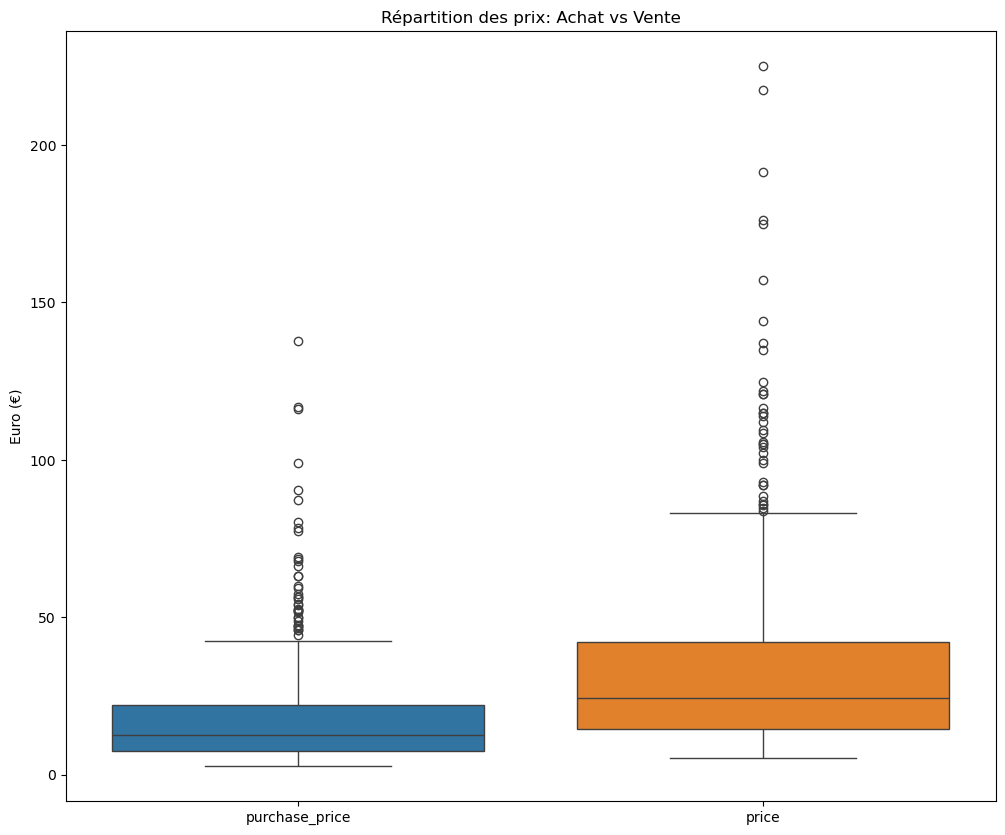

In [62]:
#Création d'une boîte à moustache de la répartition des prix grâce à Pandas
prix_total_df = total_df [['purchase_price', 'price']]

# Creiamo il boxplot
plt.figure(figsize=(12, 10))
sns.boxplot(data=prix_total_df)

plt.title("Répartition des prix: Achat vs Vente")
plt.ylabel("Euro (€)")
plt.show()

In [63]:
#Autre méthode avec plotly express
fig_total_df = px.box(total_df, y=["purchase_price", "price"], 
             title="Répartition des Prix (Achat vs Vente)",
             labels={"value": "Prix (€)", "variable": "Type de prix"})

fig_total_df.show()




In [64]:
fig_tot_ex = px.box(total_df, y=["purchase_price", "price"], 
             points="all",  # Mostra tutti i punti accanto alla scatola
             title="Prix au détail des articles (Achat vs Vente)")
fig_tot_ex.show()

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 4.2 - Exploration par l'utilisation de méthodes statistiques</h3>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 4.2.1 - Identification par le Z-index</h3>
</div>

In [65]:
#Calculer la moyenne du prix
moyenne_price = total_df['price'].mean()
print(f'Le prix moyen est de : €{moyenne_price}')
#Calculer l'écart-type (= deviazione standard) du prix
# ecart-type de la colonne price
ecart_type = total_df['price'].std()
print(f"L'écart-type est: {ecart_type}")
#CV = écart-type / moyenne (coefficient de variation ou dispertion relative) - pour comprendre si les prix sont très dispersés ou pas
cv_price = ecart_type / moyenne_price*100

print(
    f'Le coefficient de variation du prix est de : {cv_price:.2f}%, il y a une grande variabilité des prix de vente'
      )

total_df['z_scores'] = (total_df['price'] - moyenne_price) / ecart_type

#Calculer le Z-score = (valeur - moyenne) / écart-type - Colonne price
z_scores = (total_df['price'] - moyenne_price) / ecart_type
print(z_scores)

Le prix moyen est de : €32.27763636363637
L'écart-type est: 26.603195978591984
Le coefficient de variation du prix est de : 82.42%, il y a une grande variabilité des prix de vente
0     -0.303634
1      0.076020
2     -0.431438
3     -0.683288
4      0.515816
         ...   
820    0.478227
821    0.478227
822    0.846604
823   -0.217178
824   -0.600591
Name: price, Length: 825, dtype: float64


In [66]:
print(total_df[(total_df['z_scores'] > 2) & (total_df['z_scores'] <= 3)]) # les produits avec un z-score supérieur à 2 et inférieur ou égal à 3 sont considérés comme des outliers à risque

     product_id  onsale_web  price  stock_quantity stock_status  \
19         4055           0   86.1               0   outofstock   
66         4115           1  100.0              12      instock   
68         4132           1   88.4               7      instock   
214        4359           1   85.6             112      instock   
228        4404           1  108.5              17      instock   
231        4407           1  104.0              14      instock   
240        4582           1  109.6              18      instock   
410        4903           1  102.3              12      instock   
465        5007           1  105.0              15      instock   
466        5008           1  105.0              12      instock   
475        5025           1  112.0             136      instock   
476        5026           1   86.8             101      instock   
545        5565           1   92.0               0   outofstock   
650        5916           1   93.0               1      instoc

In [67]:
print(total_df[total_df['z_scores'] > 3])

     product_id  onsale_web  price  stock_quantity stock_status  \
208        4352           1  225.0               0   outofstock   
227        4402           1  176.0              11      instock   
230        4406           1  157.0              12      instock   
242        4594           1  144.0               0   outofstock   
411        4904           1  137.0               9      instock   
460        5001           1  217.5              18      instock   
556        5612           1  124.8              19      instock   
598        5767           1  175.0              12      instock   
635        5892           1  191.3              98      instock   
651        5917           1  122.0              12      instock   
652        5918           1  114.0              12      instock   
697        6126           1  135.0             138      instock   
703        6202           1  116.4              12      instock   
708        6212           1  115.0              16      instoc

In [68]:
#histogramme z_scores
px.histogram(
    total_df, x='z_scores', title="Distribution des Z-scores du prix de vente")

In [69]:
#Quel est le seuil prix dont le z-score est supérieur à 3?
# Calcoliamo media e deviazione standard
moy = total_df['price'].mean()
std = total_df['price'].std()

# Calcoliamo la soglia critica
z3 = moy + (3 * std)

print(f"Le seuil z-score > 3 est: {z3:.2f} €")

# Troviamo gli articoli che superano questa soglia
outliers_estremi = total_df[total_df['price'] > z3]
print(f'Le nombre de produits avec un prix exceptionnellement élevé est de : {len(outliers_estremi)}')
print(f'Il y a {len(outliers_estremi)} produits avec un prix exceptionnellement élevé, soit z-score >3, {len(outliers_estremi)/len(total_df)*100:.2f}% du total des produits')
print(f'Les nombre de produits qui ont un z-score entre 1 et 2 est de : {len(total_df[(total_df["z_scores"] > 1) & (total_df["z_scores"] <= 2)])} soit {len(total_df[(total_df["z_scores"] > 1) & (total_df["z_scores"] <= 2)])/len(total_df)*100:.2f}% du total des produits et les produits qui ont un z-score entre 2 et 3 est de : {len(total_df[(total_df["z_scores"] > 2) & (total_df["z_scores"] <= 3)])} soit {len(total_df[(total_df["z_scores"] > 2) & (total_df["z_scores"] <= 3)])/len(total_df)*100:.2f}% du total des produits')
outliers_estremi.head(20)

Le seuil z-score > 3 est: 112.09 €
Le nombre de produits avec un prix exceptionnellement élevé est de : 17
Il y a 17 produits avec un prix exceptionnellement élevé, soit z-score >3, 2.06% du total des produits
Les nombre de produits qui ont un z-score entre 1 et 2 est de : 66 soit 8.00% du total des produits et les produits qui ont un z-score entre 2 et 3 est de : 17 soit 2.06% du total des produits


,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,id_web,merge_status,sku,total_sales,product_type,post_title,post_name,_merge,z_scores
208,4352,1,225.0,0,outofstock,137.81,15940,both,15940,11.0,Champagne,Champagne Egly-Ouriet Grand Cru Millésimé 2008,champagne-egly-ouriet-grand-cru-millesime-2008,both,7.244331
227,4402,1,176.0,11,instock,78.25,3510,both,3510,3.0,Cognac,Cognac Frapin VIP XO,cognac-frapin-vip-xo,both,5.402447
230,4406,1,157.0,12,instock,69.08,7819,both,7819,4.0,Cognac,Cognac Frapin Château de Fontpinot 1989 20 Ans d'Age,cognac-frapin-chateau-de-fontpinot-1989-20-ans,both,4.688247
242,4594,1,144.0,0,outofstock,87.36,NaN,both,NaN,NaN,NaN,NaN,NaN,left_only,4.199584
411,4904,1,137.0,9,instock,67.95,14220,both,14220,3.0,Vin,Domaine Des Croix Corton Charlemagne Grand Cru 2016,domaine-des-croix-corton-charlemagne-grand-cru-2016,both,3.936458
460,5001,1,217.5,18,instock,116.87,14581,both,14581,2.0,Vin,David Duband Charmes-Chambertin Grand Cru 2014,david-duband-charmes-chambertin-grand-cru-2014,both,6.962410
556,5612,1,124.8,19,instock,66.41,14915,both,14915,1.0,Vin,Domaine Weinbach Gewurztraminer Grand Cru Furstentum SGN 2010 1/2,domaine-weinbach-gewurztraminer-gc-furstentum-sgn-2010,both,3.477866
598,5767,1,175.0,12,instock,90.42,15185,both,15185,4.0,Vin,Camille Giroud Clos de Vougeot 2016,camille-giroud-clos-de-vougeot-2016,both,5.364858
635,5892,1,191.3,98,instock,116.06,14983,both,14983,6.0,Champagne,Coteaux Champenois Egly-Ouriet Ambonnay Rouge 2016,coteaux-champenois-egly-ouriet-ambonnay-rouge-2016,both,5.977566
651,5917,1,122.0,12,instock,54.24,14775,both,14775,3.0,Whisky,Wemyss Malts Single Cask Scotch Whisky Choc 'n' Nut Pretzel 2001 Bunnahabhain,wemyss-malts-single-cask-scotch-whisky-choc-n-nut-pretzel-2001,both,3.372616


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 4.2.2 - Identification par l'intervalle interquartile</h3>
</div>

In [70]:
#Utilisation de la fonction "describe" de Pandas pour l'étude des mesures de dispersion - regarder mieux interquartile 
describe = total_df['price'].describe()
print(describe)

count    825.000000
mean      32.277636
std       26.603196
min        5.200000
25%       14.500000
50%       24.300000
75%       42.000000
max      225.000000
Name: price, dtype: float64


In [71]:
#Définir un seuil pour les articles "outliers" en prix
Q1 = total_df['price'].quantile(0.25)
Q3 = total_df['price'].quantile(0.75)
IQR = Q3 - Q1

upper_bound = Q3 + 1.5 * IQR

outliers_df = total_df[ total_df['price'] > upper_bound ]
print(f"Le seuil pour les outliers en prix est de: {upper_bound:.2f} €")
#Définir le nombre d'articles et la proportion de l'ensemble du catalogue "outliers"
df_outliers_prix = total_df.loc[ total_df['price'] > upper_bound ]
print(f"Nombre d'articles outliers : {len(df_outliers_prix)}")
print(f"Proportion de l'ensemble du catalogue : {len(df_outliers_prix)/len(total_df)*100:.2f}%")
df_outliers_prix.sort_values(by='price', ascending=False).head()

#Selon vous, ces outliers sont-ils justifiés ? Comment le démontrer si cela est possible ?
#oui, juste les prix d'achat sont élevés

Le seuil pour les outliers en prix est de: 83.25 €
Nombre d'articles outliers : 36
Proportion de l'ensemble du catalogue : 4.36%


,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,id_web,merge_status,sku,total_sales,product_type,post_title,post_name,_merge,z_scores
208,4352,1,225.0,0,outofstock,137.81,15940,both,15940,11.0,Champagne,Champagne Egly-Ouriet Grand Cru Millésimé 2008,champagne-egly-ouriet-grand-cru-millesime-2008,both,7.244331
460,5001,1,217.5,18,instock,116.87,14581,both,14581,2.0,Vin,David Duband Charmes-Chambertin Grand Cru 2014,david-duband-charmes-chambertin-grand-cru-2014,both,6.962410
635,5892,1,191.3,98,instock,116.06,14983,both,14983,6.0,Champagne,Coteaux Champenois Egly-Ouriet Ambonnay Rouge 2016,coteaux-champenois-egly-ouriet-ambonnay-rouge-2016,both,5.977566
227,4402,1,176.0,11,instock,78.25,3510,both,3510,3.0,Cognac,Cognac Frapin VIP XO,cognac-frapin-vip-xo,both,5.402447
598,5767,1,175.0,12,instock,90.42,15185,both,15185,4.0,Vin,Camille Giroud Clos de Vougeot 2016,camille-giroud-clos-de-vougeot-2016,both,5.364858


<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 5 - Analyse univariée du CA, des quantités vendues, des stocks et de la marge ainsi qu'une analyse multivariée  </h2>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 5.1 - Analyse des ventes en CA</h3>
</div>

In [72]:
##############################
# Calculer le CA du site web #
##############################

#Créer une colonne calculant le CA par article
total_df['ca_par_article'] = total_df['price'] * total_df['total_sales']
#Calculer la somme de la colonne "ca_par_article"
ca_total = total_df['ca_par_article'].sum()
print(f'Le chiffre d\'affaire total du site web est de : €{ca_total:.2f}')
#Ce résultat correspond au chiffre d'affaire du site web


Le chiffre d'affaire total du site web est de : €153748.10


In [73]:
total_df.head()

,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,id_web,merge_status,sku,total_sales,product_type,post_title,post_name,_merge,z_scores,ca_par_article
0,3847,1,24.2,16,instock,12.88,15298,both,15298,6.0,Vin,Pierre Jean Villa Saint-Joseph Préface 2018,pierre-jean-villa-saint-joseph-preface-2018,both,-0.303634,145.2
1,3849,1,34.3,10,instock,17.54,15296,both,15296,9.0,Vin,Pierre Jean Villa Saint-Joseph Rouge Tildé 2017,pierre-jean-villa-saint-joseph-tilde-2017,both,0.076020,308.7
2,3850,1,20.8,0,outofstock,10.64,15300,both,15300,0.0,Vin,Pierre Jean Villa Crozes-Hermitage Accroche Coeur 2018,pierre-jean-villa-croze-hermitage-accroche-coeur-2018,both,-0.431438,0.0
3,4032,1,14.1,26,instock,6.92,19814,both,19814,12.0,Vin,Pierre Jean Villa IGP Collines Rhodaniennes Gamine 2018,pierre-jean-villa-igp-gamine-2018,both,-0.683288,169.2
4,4039,1,46.0,3,instock,23.77,19815,both,19815,3.0,Vin,Pierre Jean Villa Côte Rôtie Carmina 2017,pierre-jean-villa-cote-rotie-carmina-2017,both,0.515816,138.0


In [74]:
###############################
# Palmarès des articles en CA #
###############################

#Effectuer le tri dans l'ordre décroissant du CA du dataset df_merge
total_df = total_df.sort_values(by='ca_par_article', ascending=False)
#Réinitialiser l'index du dataset par un reset_index
total_df = total_df.reset_index(drop=True)

#Afficher les 20 premiers articles en CA
total_df_top20=total_df.head(20)
total_df_top20 = total_df_top20.sort_values(by='ca_par_article', ascending=True)
#Graphique en barre des 20 premiers articles avec plotly express
fig_top20 = px.bar(total_df_top20, x='ca_par_article', y='post_title',
                  labels={'post_title': 'Article', 'ca_par_article': 'Chiffre d\'affaire (€)'},
                  text='ca_par_article')
fig_top20.update_traces(texttemplate='€%{text:.2f}', textposition='outside')
fig_top20.update_layout(xaxis_tickangle=-55)
fig_top20.show()    

In [75]:
#############################
# Calculer le 20 / 80 en CA #
#############################

#drop des artciles qui ont pas de CA dans un nouveau df. si besoin check, total_df_ca.info()

total_df_ca = total_df[total_df['ca_par_article'] > 0]
total_df_ca = total_df_ca.copy()

#Calculer le CA total du site web
ca_total = total_df_ca['ca_par_article'].sum()
print(f'Le chiffre d\'affaire total du site web est de : €{ca_total:.2f}')



Le chiffre d'affaire total du site web est de : €153748.10


In [76]:
print(len(total_df_ca))
#cacluler le CA
ca_total = total_df_ca['ca_par_article'].sum()
print(f'Le total du CA est de {ca_total:.2f} €')
# % du CA pour article
total_df_ca['part_ca_%'] = (total_df_ca['ca_par_article'] / ca_total) * 100
#Calculer le CA cumulé
total_df_ca['cumsum_part_ca_%'] = total_df_ca['part_ca_%'].cumsum()

#ordonner les articles par % de CA décroissant
total_df_ca = total_df_ca.sort_values(by='part_ca_%', ascending=False)

#Articles qui représentent 80% du CA
total_df_80 = total_df_ca[total_df_ca['cumsum_part_ca_%'] <= 80]
print(f"Nombre d'articles représentant 80 % du CA : {len(total_df_80)}")
proportion_80 = (len(total_df_80) / len(total_df_ca)) * 100
print(f"Proportion d'articles : {proportion_80:.2f} %")

689
Le total du CA est de 153748.10 €
Nombre d'articles représentant 80 % du CA : 420
Proportion d'articles : 60.96 %


In [77]:
#ajouter la colonne cumsum et calcul du CA au df total_df
# % du CA pour article
total_df['part_ca_%'] = (total_df['ca_par_article'] / ca_total) * 100
#Calculer le CA cumulé
total_df['cumsum_part_ca_%'] = total_df['part_ca_%'].cumsum()
#ordonner les articles par % de CA décroissant
total_df = total_df.sort_values(by='part_ca_%', ascending=False)
total_df.head()

,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,id_web,merge_status,sku,total_sales,product_type,post_title,post_name,_merge,z_scores,ca_par_article,part_ca_%,cumsum_part_ca_%
0,4150,1,59.0,123,instock,35.45,1366,both,1366,116.0,Champagne,Champagne Mailly Grand Cru Intemporelle 2010,champagne-mailly-grand-cru-intemporelle-2010,both,1.004479,6844.0,4.451437,4.451437
1,4352,1,225.0,0,outofstock,137.81,15940,both,15940,11.0,Champagne,Champagne Egly-Ouriet Grand Cru Millésimé 2008,champagne-egly-ouriet-grand-cru-millesime-2008,both,7.244331,2475.0,1.609776,6.061213
2,4726,1,12.7,0,outofstock,6.82,14950,both,14950,122.0,Vin,François Baur Pinot Noir Schlittweg 2017,francois-baur-pinot-noir-schlittweg-2017,both,-0.735913,1549.4,1.007752,7.068965
3,5067,1,59.9,3,instock,30.95,15346,both,15346,22.0,Vin,Albert Mann Pinot Noir Grand H 2017,albert-mann-pinot-noir-grand-h-2017,both,1.038310,1317.8,0.857116,7.926082
4,5379,1,11.1,33,instock,5.68,14561,both,14561,111.0,Vin,Argentine Mendoza Alamos Torrontes 2017,argentine-mendoza-alamos-torrontes-2017,both,-0.796056,1232.1,0.801376,8.727457


In [78]:
# Creiamo un grafico a linea per vedere la "curva"
fig_paretto = px.line(
    total_df_ca.reset_index(),
    x=total_df_ca.index,
    y="cumsum_part_ca_%",
    title="Courbe de Pareto (Facturée accumulée)",
    hover_name="post_title",
    labels={
        "x": "Produits (ordonnés par importance)",
        "cumsum_part_ca_%": "% accumulé du CA"
    }
)

# Aggiungiamo una linea orizzontale all'80% per riferimento
fig_paretto.add_hline(y=80, line_dash="dash", line_color="red", annotation_text="Soglia 80%")

fig_paretto.show()

In [79]:
#analyse du CA par produit pour trouver le z-score et les outliers en prix. calculer deviazione standard par produit par rapport au CA, calculer le CV e puis le z-score de chaque produit par rapport au CA pour trouver les produits qui ont un CA exceptionnellement élevé et qui pourraient être des outliers en CA.
#Calculer la moyenne du prix
moyenne_ca = total_df['ca_par_article'].mean()
print(f'Le CA moyen est de : €{moyenne_ca:.2f}')
#Calculer l'écart-type (= deviazione standard) du prix
# ecart-type de la colonne price
ecart_type_ca = total_df['ca_par_article'].std()
print(f"L'écart-type est: {ecart_type_ca:.2f}")
#CV = écart-type / moyenne (coefficient de variation ou dispertion relative) - pour comprendre si les prix sont très dispersés ou pas
cv_ca = ecart_type_ca / moyenne_ca*100

print(
    f'Le coefficient de variation du CA est de : {cv_ca:.2f}%, il y a une grande variabilité des CA des produits'
      )

total_df['z_scores_ca'] = (total_df['ca_par_article'] - moyenne_ca) / ecart_type_ca

#Calculer le Z-score = (valeur - moyenne) / écart-type - Colonne price
z_scores_ca = (total_df['ca_par_article'] - moyenne_ca) / ecart_type_ca
print(z_scores_ca)

Le CA moyen est de : €215.33
L'écart-type est: 301.76
Le coefficient de variation du CA est de : 140.14%, il y a une grande variabilité des CA des produits
0      21.966510
1       7.488231
2       4.420917
3       3.653426
4       3.369428
         ...    
820          NaN
821          NaN
822          NaN
823          NaN
824          NaN
Name: ca_par_article, Length: 825, dtype: float64


In [80]:
#histogramme z_scores
px.histogram(
    total_df, x='z_scores_ca', title="Distribution des Z-scores du CA par article")

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 5.2 - Analyse des ventes en quantité</h3>
</div>

In [81]:
#####################################
# Palmarès des articles en quantité #
#####################################
#Effectuer le tri dans l'ordre décroissant de quantités vendues du dataset df_merge
total_df=total_df.sort_values(by='total_sales', ascending=False)

#Réinitialiser l'index du dataset par un reset_index
total_df = total_df.reset_index(drop=True)
#Afficher les 20 premiers articles en quantité
total_df.head()

,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,id_web,merge_status,sku,total_sales,product_type,post_title,post_name,_merge,z_scores,ca_par_article,part_ca_%,cumsum_part_ca_%,z_scores_ca
0,4726,1,12.7,0,outofstock,6.82,14950,both,14950,122.0,Vin,François Baur Pinot Noir Schlittweg 2017,francois-baur-pinot-noir-schlittweg-2017,both,-0.735913,1549.4,1.007752,7.068965,4.420917
1,4150,1,59.0,123,instock,35.45,1366,both,1366,116.0,Champagne,Champagne Mailly Grand Cru Intemporelle 2010,champagne-mailly-grand-cru-intemporelle-2010,both,1.004479,6844.0,4.451437,4.451437,21.966510
2,5379,1,11.1,33,instock,5.68,14561,both,14561,111.0,Vin,Argentine Mendoza Alamos Torrontes 2017,argentine-mendoza-alamos-torrontes-2017,both,-0.796056,1232.1,0.801376,8.727457,3.369428
3,4867,1,9.9,121,instock,4.86,16148,both,16148,36.0,Vin,Château De La Selve IGP Coteaux de l'Ardèche Maguelonne Rosé 2019,chateau-de-la-selve-igp-coteaux-de-lardeche-maguelonne-rose-2019,both,-0.841163,356.4,0.231808,28.424026,0.467476
4,4203,1,9.9,74,instock,5.01,15415,both,15415,27.0,Vin,Mas Laval IGP Pays d'Hérault Les Pampres Blancs 2018,mas-laval-igp-pays-herault-pampres-blanc-2018,both,-0.841163,267.3,0.173856,44.309751,0.172210


In [82]:
#df top 20 quantite vendue
total_df=total_df.sort_values(by='total_sales', ascending=False)

total_df_top20_ventes = total_df.head(20)
total_df_top20_ventes = total_df_top20_ventes.sort_values(by='total_sales', ascending=True)
#Graphique en barre des 20 premiers articles avec plotly express
fig_52 = px.bar(total_df_top20_ventes, x='total_sales', y='post_title',
               )
fig_52.show()

In [83]:
#############################
# Calculer le 20 / 80 en quantité vendues #
#############################

#Créer une colonne calculant la part en quantité (total_sales)  de la ligne dans le dataset
total_df['part_quantite_%'] = (total_df['total_sales'] / total_df['total_sales'].sum()) * 100

#Créer une colonne réalisant la somme cumulative de la colonne précedemment créée
total_df['cumulative_q_part_%'] = total_df['part_quantite_%'].cumsum()

#Grâce aux deux colonnes créées précedemment, calculer le nombre d'articles représentant 80% des ventes en quantité
total_df_80_quantity = total_df[total_df['cumulative_q_part_%'] <= 80]
proportion_80_quantity = (len(total_df_80_quantity) / len(total_df)) * 100
#Afficher la proportion que représente ce groupe d'articles dans le catalogue entier du site web
print(f"Nombre d'articles représentant 80 % des quantité vendues : {len(total_df_80_quantity)}")
print(f"Proportion d'articles : {proportion_80_quantity:.2f} %")

Nombre d'articles représentant 80 % des quantité vendues : 424
Proportion d'articles : 51.39 %


In [84]:
print(f'le total de produits vendus est de {total_df["total_sales"].sum():.0f}')
total_df.sort_values(by='total_sales', ascending=False).head(3)
#somma dei primi 3 produits vendus
print(f'le total des quantités vendues des 3 premiers produits est de {total_df.sort_values(by="total_sales", ascending=False).head(3)["total_sales"].sum():.0f}, qui correspond à {total_df.sort_values(by="total_sales", ascending=False).head(3)["total_sales"].sum()/total_df["total_sales"].sum()*100:.2f}% du total des quantités vendues')

le total de produits vendus est de 6081
le total des quantités vendues des 3 premiers produits est de 349, qui correspond à 5.74% du total des quantités vendues


In [85]:
#z-score quantité vendue
moyenne_sales = total_df['total_sales'].mean()
print(f'Le nombre moyen de ventes est de : {moyenne_sales:.2f}')
#Calculer l'écart-type (= deviazione standard) du prix
# ecart-type de la colonne price
ecart_type_sales = total_df['total_sales'].std()
print(f"L'écart-type est: {ecart_type_sales:.2f}")
#CV = écart-type / moyenne (coefficient de variation ou dispertion relative) - pour comprendre si les prix sont très dispersés ou pas
cv_sales = ecart_type_sales / moyenne_sales*100

print(
    f'Le coefficient de variation du nombre de ventes est de : {cv_sales:.2f}%, il y a une grande variabilité des ventes des produits'
      )

total_df['z_scores_sales'] = (total_df['total_sales'] - moyenne_sales) / ecart_type_sales

Le nombre moyen de ventes est de : 8.52
L'écart-type est: 8.15
Le coefficient de variation du nombre de ventes est de : 95.71%, il y a une grande variabilité des ventes des produits


In [86]:
#graphique z_scores_sales
#histogramme z_scores
px.histogram(
    total_df, x='z_scores_sales', title="Distribution des Z-scores du nombre de ventes par article")

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 5.3 - Analyse des stocks</h3>
</div>

In [87]:

df_merged.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 825 entries, 0 to 824
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype   
---  ------          --------------  -----   
 0   product_id      825 non-null    int64   
 1   onsale_web      825 non-null    int64   
 2   price           825 non-null    float64 
 3   stock_quantity  825 non-null    int64   
 4   stock_status    825 non-null    object  
 5   purchase_price  825 non-null    float64 
 6   id_web          734 non-null    object  
 7   merge_status    825 non-null    category
dtypes: category(1), float64(2), int64(3), object(2)
memory usage: 46.2+ KB


In [88]:
######################################
# Calculer le nombre de mois de stock #
######################################

#Import de numpy 

#Création de la colonne Rotation de stock - c'est plutot un indice de lenteur un chiffre plus élevé indique que le stock tourne moins vite,
# c'est à dire que les produits se vendent moins; un chiffre plus bas indique que le stock tourne plus vite, c'est à dire que les produits se vendent plus
total_df['rotation_stock'] = total_df['stock_quantity'] / total_df['total_sales']
#Remplacement des "inf" par 0
total_df['rotation_stock'] = total_df['rotation_stock'].replace(np.inf, 0)

#Effectuer le tri dans l'ordre décroissant du nombre de mois de stock dans le dataset df_merge
total_df=total_df.sort_values(by='rotation_stock', ascending=False)
#Graphique en barre du flop 20 des produits qui ne vendent pas
flo20_rotation_stock = total_df.head(20)
#ordonner les produits du flop 20 par rotation de stock décroissante pour que le produit qui se vend le moins soit en premier
flo20_rotation_stock = flo20_rotation_stock.sort_values(by='rotation_stock', ascending=True)
fig_53 = px.bar(flo20_rotation_stock, x='rotation_stock', y='post_title')
fig_53.show()


In [89]:
rotation_stock = total_df[['product_id','rotation_stock', 'total_sales', 'stock_quantity', 'post_title', 'price', 'purchase_price']]
rotation_stock = rotation_stock.dropna(subset=['rotation_stock'])
rotation_stock.tail(20)

,product_id,rotation_stock,total_sales,stock_quantity,post_title,price,purchase_price
272,4256,0.0,9.0,0,Domaine Huet Vouvray Haut-Lieu Sec 2017,24.40,12.61
18,4870,0.0,16.0,0,Triennes IGP Méditerranée Rosé 2019,9.30,4.81
32,4241,0.0,15.0,0,Parcé Frères IGP Côtes Catalanes Hommage à Fernand Blanc 2019,8.90,4.37
43,5930,0.0,14.0,0,Borie La Vitarèle Languedoc Blanc Le Grand Mayol 2019,14.10,6.92
168,4352,0.0,11.0,0,Champagne Egly-Ouriet Grand Cru Millésimé 2008,225.00,137.81
202,4885,0.0,10.0,0,Saumaize-Michelin Mâcon Vergisson Sur La Roche 2017,18.70,9.66
203,4706,0.0,10.0,0,Albert Mann Muscat 2018,16.80,8.68
295,5487,0.0,9.0,0,Decelle-Villa Nuits-Saint-Georges Rouge 2016,43.50,23.37
315,5617,0.0,9.0,0,Albert Boxler Pinot Gris Réserve 2016,27.80,14.65
358,4274,0.0,8.0,0,Domaine Sérol Vin Mousseux Rosé Turbullent Méthode Ancestrale,12.90,6.33


In [90]:
####################################
# Valorisation des stocks en euros #
####################################

#Création de la colonne Valorisation des stocks en euros
total_df['Valorisation_stock_euro']= total_df['stock_quantity'] * total_df['purchase_price']
#Calculer la somme de la colonne "Valorisation_stock_euros"
valorisation_stock_total= total_df['Valorisation_stock_euro'].sum()
print(f'La valorisation totale des stocks est de : €{valorisation_stock_total:.2f}')

La valorisation totale des stocks est de : €298627.66


In [91]:
##############################################
# Valorisation du nombre de produits en stock #
##############################################

#Calculer la somme de la colonne stock quantity
total_quantity_in_stock = total_df['stock_quantity'].sum()
print(f'Le nombre total de produits en stock est de : {total_quantity_in_stock}')
#calculer la valeur moyenne du stock par article
average_stock_per_article = total_quantity_in_stock / len(total_df)
print(f'La valeur moyenne du stock par article est de : {average_stock_per_article:.2f}')

Le nombre total de produits en stock est de : 17822
La valeur moyenne du stock par article est de : 21.60


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 5.4 - Analyse du taux de marge</h3>
</div>

In [92]:
############################
# Analyse du taux de marge #
############################

#Création de la colonne Prix HT
total_df['price_ht'] = (total_df['price'] * 1.2) # Supposant une TVA de 20%
#Création de la colonne Taux de marge
total_df['taux_marge'] = (total_df['price_ht'] - total_df['purchase_price']) / total_df['price_ht'] * 100
#Afficher le prix minimum de la colonne "taux_marge"
print(f'Le taux de marge minimum est de : {total_df["taux_marge"].min():.2f}%')
#Afficher le prix maximum de la colonne "taux_marge"
print(f'Le taux de marge maximum est de : {total_df["taux_marge"].max():.2f}%')

Le taux de marge minimum est de : -410.41%
Le taux de marge maximum est de : 63.72%


In [93]:
#Affichage de la ligne avec un taux de marge inférieur à 0
df_marge_negatif = total_df[total_df['taux_marge'] < 0]
print(f'Le nombre de produits avec un taux de marge négatif est de : {len(df_marge_negatif)}')
df_marge_negatif.head()



Le nombre de produits avec un taux de marge négatif est de : 2


,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,id_web,merge_status,sku,total_sales,product_type,post_title,post_name,_merge,z_scores,ca_par_article,part_ca_%,cumsum_part_ca_%,z_scores_ca,part_quantite_%,cumulative_q_part_%,z_scores_sales,rotation_stock,Valorisation_stock_euro,price_ht,taux_marge
710,4355,1,12.65,97,instock,77.48,12589,both,12589,0.0,Champagne,Champagne Egly-Ouriet Grand Cru Blanc de Noirs,champagne-egly-ouriet-grand-cru-brut-blanc-de-noirs,both,-0.737792,0.0,0.0,100.0,-0.713586,0.0,100.0,-1.044797,0.0,7515.56,15.18,-410.408432
741,4864,0,8.30,0,outofstock,9.99,15154,both,NaN,NaN,NaN,NaN,NaN,left_only,-0.901307,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00,9.96,-0.301205


In [94]:
#Création d'un dataframe avec les taux positifs
df_total_positive_margin = total_df[total_df['taux_marge'] >= 0]
#Afficher le prix minimum de la colonne "taux_marge"
print(f'Le taux de marge minimum est de : {df_total_positive_margin["taux_marge"].min():.2f}%')
#Afficher le prix maximum de la colonne "taux_marge"
print(f'Le taux de marge maximum est de : {df_total_positive_margin["taux_marge"].max():.2f}%')

Le taux de marge minimum est de : 10.33%
Le taux de marge maximum est de : 63.72%


In [95]:
#filtrare df_total_positive_margin unicamente per valori non nulli in post_title
df_total_positive_margin = df_total_positive_margin[df_total_positive_margin['post_title'].notnull()]

In [96]:
# Troviamo la riga (l'indice) del prodotto con il margine % massimo e minimo
indice_max_marge = df_total_positive_margin['taux_marge'].idxmax()
indice_min_marge = df_total_positive_margin['taux_marge'].idxmin()

# Estraiamo il prezzo (e magari il nome) di quel prodotto
prix_du_max_marge = df_total_positive_margin.loc[indice_max_marge, 'price']
nom_produit_max = df_total_positive_margin.loc[indice_max_marge, 'post_title']

prix_du_min_marge = df_total_positive_margin.loc[indice_min_marge, 'price']
nom_produit_min = df_total_positive_margin.loc[indice_min_marge, 'post_title']
print(f"Le produit avec le taux de marge le plus élevé est: {nom_produit_max}")
print(f"Son prix de vente est: {prix_du_max_marge:.2f} €")
print(f"Le produit avec le taux de marge le plus bas est: {nom_produit_min}")
print(f"Son prix de vente est: {prix_du_min_marge:.2f} €")

Le produit avec le taux de marge le plus élevé est: Cognac Frapin VSOP
Son prix de vente est: 62.50 €
Le produit avec le taux de marge le plus bas est: Huile d'Olive Extra Vierge Planeta 50cl
Son prix de vente est: 13.10 €


In [97]:
# Troviamo la riga (l'indice) del prodotto con il margine % massimo e minimo
indice_max_marge = total_df['taux_marge'].idxmax()
indice_min_marge = total_df['taux_marge'].idxmin()

# Estraiamo il prezzo (e magari il nome) di quel prodotto
prix_du_max_marge = total_df.loc[indice_max_marge, 'price']
nom_produit = total_df.loc[indice_max_marge, 'post_title']

prix_du_min_marge = total_df.loc[indice_min_marge, 'price']
nom_produit_min = total_df.loc[indice_min_marge, 'post_title']
print(f"Le produit avec le taux de marge le plus élevé est: {nom_produit}")
print(f"Son prix de vente est: {prix_du_max_marge:.2f} €")
print(f"Le produit avec le taux de marge le plus bas est: {nom_produit_min}")
print(f"Son prix de vente est: {prix_du_min_marge:.2f} €")

Le produit avec le taux de marge le plus élevé est: Cognac Frapin VSOP
Son prix de vente est: 62.50 €
Le produit avec le taux de marge le plus bas est: Champagne Egly-Ouriet Grand Cru Blanc de Noirs
Son prix de vente est: 12.65 €


In [98]:
#Utiliser ABC pour classer les produits.
# Classe A : les produits qui représentent 80% du CA
# Classe B : les produits qui représentent entre 80% et 95% du CA
# Classe C : les produits qui représentent les 5% restants du CA

In [99]:
print(total_df['rotation_stock'].min(), total_df['rotation_stock'].max())


0.0 31.25


In [100]:
#creazione colonna ABC selon cumsum part_ca_%
# A : produits qui représentent jusqu'au 80% du CA
# B: produits qui représentent entre 80% et 95% du CA
# C: produits qui représentent plus de 95% du CA
def get_ABC(row):
    if row['cumsum_part_ca_%'] <= 80:
        return 'A'
    elif row['cumsum_part_ca_%'] <= 95:
        return 'B'
    else:
        return 'C'

total_df['ABC'] = total_df.apply(get_ABC, axis=1)

for cat in ['A', 'B', 'C']:
    print(f"{cat}: {total_df['ABC'].value_counts().get(cat, 0)}")


A: 420
B: 180
C: 225


In [101]:
#Critere ABC pour les produits
# REORDER : les produits de classe A avec une rotation de stock inférieure ou égale à 1.5 et un taux de marge positif
# PROMO : les produits de classe B ou C avec une rotation de stock supérieure ou égale à 3 et un taux de marge positif
# CHECK : les produits avec un taux de marge négatif, ou un z-score du CA supérieur à 3, 
# ou les produits de classe A avec une rotation de stock supérieure ou égale à 3, 
# ou les produits avec une rotation de stock supérieure ou égale à 10
def get_action_flag(row):
    ABC = row['ABC']
    rot = row['rotation_stock']
    marge = row['taux_marge']
    z = row['z_scores_ca']

    # CHECK (priority)
    if marge < 0:
        return 'check'
    if abs(z) > 3:
        return 'check'
    if ABC == 'A' and rot >= 3:
        return 'check'
    if rot >= 10:
        return 'check'

    # REORDER
    if ABC == 'A' and rot <= 1.5 and marge > 0:
        return 'reorder'

    # PROMO
    if ABC in ['B', 'C'] and rot >= 3 and marge > 0:
        return 'promo'

    return 'none'

total_df['action_flag'] = total_df.apply(get_action_flag, axis=1)



In [102]:
print(total_df[(total_df['ABC'].isin(['B','C'])) & (total_df['rotation_stock'] >= 4)].shape[0])


4


In [103]:
#ordonner les produits par part_ca_% décroissant
total_df = total_df.sort_values(by='part_ca_%', ascending=False)
total_df.head()

,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,id_web,merge_status,sku,total_sales,product_type,post_title,post_name,_merge,z_scores,ca_par_article,part_ca_%,cumsum_part_ca_%,z_scores_ca,part_quantite_%,cumulative_q_part_%,z_scores_sales,rotation_stock,Valorisation_stock_euro,price_ht,taux_marge,ABC,action_flag
1,4150,1,59.0,123,instock,35.45,1366,both,1366,116.0,Champagne,Champagne Mailly Grand Cru Intemporelle 2010,champagne-mailly-grand-cru-intemporelle-2010,both,1.004479,6844.0,4.451437,4.451437,21.966510,1.907581,3.913830,13.185469,1.060345,4360.35,70.80,49.929379,A,check
168,4352,1,225.0,0,outofstock,137.81,15940,both,15940,11.0,Champagne,Champagne Egly-Ouriet Grand Cru Millésimé 2008,champagne-egly-ouriet-grand-cru-millesime-2008,both,7.244331,2475.0,1.609776,6.061213,7.488231,0.180891,43.101464,0.304625,0.000000,0.00,270.00,48.959259,A,check
0,4726,1,12.7,0,outofstock,6.82,14950,both,14950,122.0,Vin,François Baur Pinot Noir Schlittweg 2017,francois-baur-pinot-noir-schlittweg-2017,both,-0.735913,1549.4,1.007752,7.068965,4.420917,2.006249,2.006249,13.921518,0.000000,0.00,15.24,55.249344,A,check
6,5067,1,59.9,3,instock,30.95,15346,both,15346,22.0,Vin,Albert Mann Pinot Noir Grand H 2017,albert-mann-pinot-noir-grand-h-2017,both,1.038310,1317.8,0.857116,7.926082,3.653426,0.361783,7.531656,1.654047,0.136364,92.85,71.88,56.942126,A,check
2,5379,1,11.1,33,instock,5.68,14561,both,14561,111.0,Vin,Argentine Mendoza Alamos Torrontes 2017,argentine-mendoza-alamos-torrontes-2017,both,-0.796056,1232.1,0.801376,8.727457,3.369428,1.825358,5.739188,12.572096,0.297297,187.44,13.32,57.357357,A,check


In [104]:
#compter combien de produits ont le flag "check", "reorder", "promo"
check_count = total_df['action_flag'].value_counts()
print(check_count)

action_flag
none       512
check      127
reorder     96
promo       90
Name: count, dtype: int64


In [105]:
for flag in ['check', 'reorder', 'promo']:
    print(f"{flag}: {total_df['action_flag'].value_counts().get(flag, 0)}")

check: 127
reorder: 96
promo: 90


In [106]:
df_reorder = total_df[total_df['action_flag'] == 'reorder']

print(f'Le nombre de produits à réapprovisionner est de : {len(df_reorder)}')

df_promo = total_df[total_df['action_flag'] == 'promo']
print(f'Le nombre de produits à promouvoir est de : {len(df_promo)}')

df_check = total_df[total_df['action_flag'] == 'check']
print(f'Le nombre de produits à vérifier est de : {len(df_check)}')
df_check.head()

Le nombre de produits à réapprovisionner est de : 96
Le nombre de produits à promouvoir est de : 90
Le nombre de produits à vérifier est de : 127


,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,id_web,merge_status,sku,total_sales,product_type,post_title,post_name,_merge,z_scores,ca_par_article,part_ca_%,cumsum_part_ca_%,z_scores_ca,part_quantite_%,cumulative_q_part_%,z_scores_sales,rotation_stock,Valorisation_stock_euro,price_ht,taux_marge,ABC,action_flag
1,4150,1,59.0,123,instock,35.45,1366,both,1366,116.0,Champagne,Champagne Mailly Grand Cru Intemporelle 2010,champagne-mailly-grand-cru-intemporelle-2010,both,1.004479,6844.0,4.451437,4.451437,21.966510,1.907581,3.913830,13.185469,1.060345,4360.35,70.80,49.929379,A,check
168,4352,1,225.0,0,outofstock,137.81,15940,both,15940,11.0,Champagne,Champagne Egly-Ouriet Grand Cru Millésimé 2008,champagne-egly-ouriet-grand-cru-millesime-2008,both,7.244331,2475.0,1.609776,6.061213,7.488231,0.180891,43.101464,0.304625,0.000000,0.00,270.00,48.959259,A,check
0,4726,1,12.7,0,outofstock,6.82,14950,both,14950,122.0,Vin,François Baur Pinot Noir Schlittweg 2017,francois-baur-pinot-noir-schlittweg-2017,both,-0.735913,1549.4,1.007752,7.068965,4.420917,2.006249,2.006249,13.921518,0.000000,0.00,15.24,55.249344,A,check
6,5067,1,59.9,3,instock,30.95,15346,both,15346,22.0,Vin,Albert Mann Pinot Noir Grand H 2017,albert-mann-pinot-noir-grand-h-2017,both,1.038310,1317.8,0.857116,7.926082,3.653426,0.361783,7.531656,1.654047,0.136364,92.85,71.88,56.942126,A,check
2,5379,1,11.1,33,instock,5.68,14561,both,14561,111.0,Vin,Argentine Mendoza Alamos Torrontes 2017,argentine-mendoza-alamos-torrontes-2017,both,-0.796056,1232.1,0.801376,8.727457,3.369428,1.825358,5.739188,12.572096,0.297297,187.44,13.32,57.357357,A,check


In [107]:
print(total_df['rotation_stock'].median())


2.4


In [108]:
#Pour le df_check, création colonne avec explication de pourquoi le produit a été flaggé "check"
def raison_check(row):
    raisons = []

    # 1. Margine negativo
    if row['taux_marge'] < 0:
        raisons.append("Marge negatif")

    # 2. Outlier sul fatturato
    if abs(row['z_scores_ca']) > 3:
        raisons.append(f"Outlier CA (z={row['z_scores_ca']:.2f})")

    # 3. Prodotto A ma lento
    if row['ABC'] == 'A' and row['rotation_stock'] >= 3:
        raisons.append("Produit A lent à vendre")

    # 4. Stock enorme rispetto alle vendite
    if row['rotation_stock'] >= 10:
        raisons.append("Stock très élevé par rapport aux ventes")

    # Se per qualche motivo è in check ma non ha motivi espliciti
    if len(raisons) == 0:
        raisons.append("Check (verifica manuale)")

    return " | ".join(raisons)


# Filtra solo i prodotti in check
#filtre des produits avec action_flag "check"
df_check = total_df[total_df['action_flag'] == 'check'].copy()

# Aggiungi la colonna con il motivo
#ajouter la colonne avec le motif du check
df_check['raison_check'] = df_check.apply(raison_check, axis=1)

# Seleziona solo le colonne utili
#selectionner les colonnes utiles pour le rapport de check
report_check = df_check[[
    'product_id',
    'post_title',
    'ABC',
    'rotation_stock',
    'taux_marge',
    'z_scores_ca',
    'stock_quantity',
    'total_sales',
    'raison_check'
]]

report_check.head(20)


,product_id,post_title,ABC,rotation_stock,taux_marge,z_scores_ca,stock_quantity,total_sales,raison_check
1,4150,Champagne Mailly Grand Cru Intemporelle 2010,A,1.060345,49.929379,21.966510,123,116.0,Outlier CA (z=21.97)
168,4352,Champagne Egly-Ouriet Grand Cru Millésimé 2008,A,0.000000,48.959259,7.488231,0,11.0,Outlier CA (z=7.49)
0,4726,François Baur Pinot Noir Schlittweg 2017,A,0.000000,55.249344,4.420917,0,122.0,Outlier CA (z=4.42)
6,5067,Albert Mann Pinot Noir Grand H 2017,A,0.136364,56.942126,3.653426,3,22.0,Outlier CA (z=3.65)
2,5379,Argentine Mendoza Alamos Torrontes 2017,A,0.297297,57.357357,3.369428,33,111.0,Outlier CA (z=3.37)
504,5892,Coteaux Champenois Egly-Ouriet Ambonnay Rouge 2016,A,16.333333,49.442412,3.090069,98,6.0,Outlier CA (z=3.09) | Produit A lent à vendre | Stock très élevé par rapport aux ventes
52,4353,Champagne Egly-Ouriet Grand Cru Brut Rosé,A,9.071429,51.876310,2.974746,127,14.0,Produit A lent à vendre
311,5026,Champagne Agrapart &amp; Fils Minéral Extra Brut Blanc de Blancs Grand Cru 2012,A,11.222222,51.872120,1.875206,101,9.0,Produit A lent à vendre | Stock très élevé par rapport aux ventes
609,5767,Camille Giroud Clos de Vougeot 2016,A,3.000000,56.942857,1.606120,12,4.0,Produit A lent à vendre
526,6126,Champagne Gosset Célébris Vintage 2007,A,27.600000,50.413580,1.523273,138,5.0,Produit A lent à vendre | Stock très élevé par rapport aux ventes


In [109]:
#Création d'un dataframe avec le taux de marge moyen par type de produit
#NOus allons unitliser le df df_total_positive_margin pour ne prendre en compte que les produits avec un taux de marge positif
#Regrouper par type de produit et calculer la moyenne du taux de marge
df_marge_par_type = df_total_positive_margin.groupby('product_type')['taux_marge'].mean().round(2).reset_index()

#Ordiniamo dal tipo più redditizio a quello meno redditizio
df_marge_par_type = df_marge_par_type.sort_values(by='taux_marge', ascending=False)

display(df_marge_par_type)
#Affichage dans un graphique du taux de marge par type de produit


,product_type,taux_marge
2,Cognac,61.85
6,Whisky,61.75
3,Gin,60.28
5,Vin,56.95
0,Autre,55.67
1,Champagne,50.34
4,Huile d'olive,47.92


In [110]:
fig_54 = px.bar(df_marge_par_type, x='product_type', y='taux_marge',
                 title='Taux de marge moyen par type de produit',
                 text_auto='.2f%',
                 color = 'taux_marge',
                 color_continuous_scale=px.colors.sequential.Viridis,
                 labels={
    'product_type': 'Type de produit',
    'taux_marge': 'Taux de marge moyen (%)'
                 }
)
fig_54.show()

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 5.5 - Analyse des corrélations entre les variables stock, sales et price</h3>
</div>

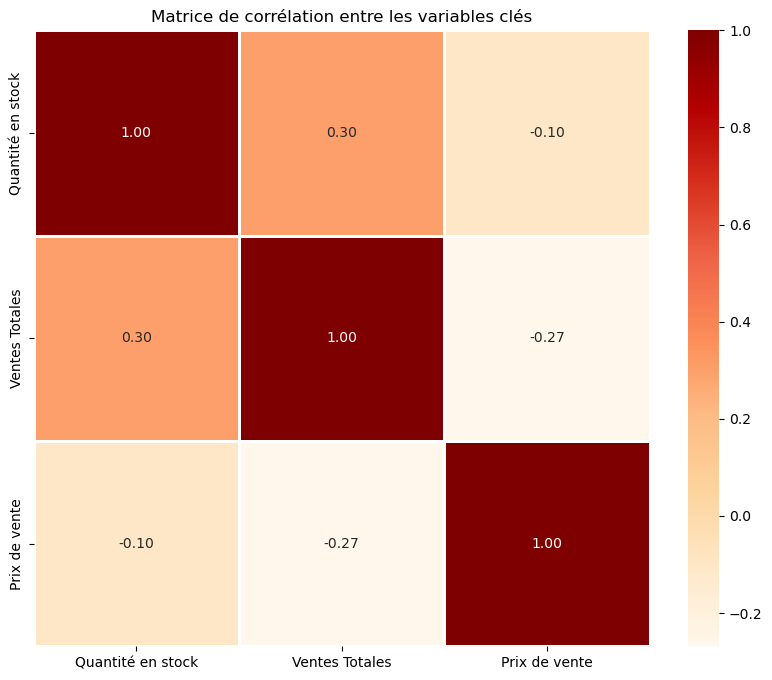

In [111]:
df_corr = df_total_positive_margin[['stock_quantity', 'total_sales', 'price']].rename(columns={
    'stock_quantity': 'Quantité en stock',
    'total_sales': 'Ventes Totales',
    'price': 'Prix de vente'
}).corr()

# 2. Creiamo il grafico
plt.figure(figsize=(10, 8)) # largeur de l'image et hauteur
sns.heatmap(df_corr, 
            annot=True,      # montre les valeurs de corrélation dans les cases
            fmt=".2f",       # juste 2 decimales
            cmap='OrRd',     # Scala di colori (Orange-Red)
            square=True,     # carrés pour les cases
            linewidths=1)   # ligne entre les carrés

plt.title('Matrice de corrélation entre les variables clés')
plt.show()

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 5.6 - Mise à disposition de la nouvelle table sur un fichier Excel</h3>
</div>

In [112]:
#Mettre le dataset df_merge sur un fichier Excel
total_df.to_excel(r"dataset_finale.xlsx", index=False)
#Cette étape peut être utile pour partager le résultat du dataset obtenu avec les équipes. 
#Export d'autres df en excel
non_match_erp.to_excel(r"non_match_erp.xlsx", index=False)
rotation_stock.to_excel(r"rotation_stock.xlsx", index=False)
df_reorder.to_excel(r"reorder.xlsx", index=False)
df_promo.to_excel(r"promo.xlsx", index=False)
df_check.to_excel(r"check.xlsx", index=False) 
